### Understanding the training data
For 4 engines we get training data as a .txt. Each row represents a single operationsal cycle whilst each row is a different variable.  
The first col is the unit number - meaning the id of the engine. We can see that for each engine the second col counts the cycles, that are run with that engine.    
Coloumn 3, 4 and 5 represent important operational settings that have a "substantial effect on engine performance"; The rest of the coloumns have sensor measurements for each cycle.


In [35]:
import pandas as pd

# loading the first training dataset
df = pd.read_csv("../CMAPSSData/train_FD001.txt", sep=r"\s+", header=None)

# checking if it loaded correctly
print(df.head(5))
print(df.info())

   0   1       2       3      4       5       6        7        8      9   \
0   1   1 -0.0007 -0.0004  100.0  518.67  641.82  1589.70  1400.60  14.62   
1   1   2  0.0019 -0.0003  100.0  518.67  642.15  1591.82  1403.14  14.62   
2   1   3 -0.0043  0.0003  100.0  518.67  642.35  1587.99  1404.20  14.62   
3   1   4  0.0007  0.0000  100.0  518.67  642.35  1582.79  1401.87  14.62   
4   1   5 -0.0019 -0.0002  100.0  518.67  642.37  1582.85  1406.22  14.62   

   ...      16       17       18      19    20   21    22     23     24  \
0  ...  521.66  2388.02  8138.62  8.4195  0.03  392  2388  100.0  39.06   
1  ...  522.28  2388.07  8131.49  8.4318  0.03  392  2388  100.0  39.00   
2  ...  522.42  2388.03  8133.23  8.4178  0.03  390  2388  100.0  38.95   
3  ...  522.86  2388.08  8133.83  8.3682  0.03  392  2388  100.0  38.88   
4  ...  522.19  2388.04  8133.80  8.4294  0.03  393  2388  100.0  38.90   

        25  
0  23.4190  
1  23.4236  
2  23.3442  
3  23.3739  
4  23.4044  

[5 rows

In [36]:
amount_of_engines = df.iloc[-1,0]
print(f"number of missing values: {df.isnull().sum().sum()}")
print(f"number of different engines: {amount_of_engines}")


number of missing values: 0
number of different engines: 100


In [37]:
lifetime = {}
for engine_id in range(amount_of_engines):
    selected_engine = df.loc[df[0] == engine_id + 1]
    lifetime[engine_id + 1] = selected_engine.iloc[-1,1]

print(f"max lifetime: {max(lifetime.values())}, on engine: {max(lifetime, key=lifetime.get)}")
print(f"min lifetime: {min(lifetime.values())}, on engine: {min(lifetime, key=lifetime.get)}")
print(f"average lifetime: {sum(lifetime.values()) / len(lifetime)}")

max lifetime: 362, on engine: 69
min lifetime: 128, on engine: 39
average lifetime: 206.31


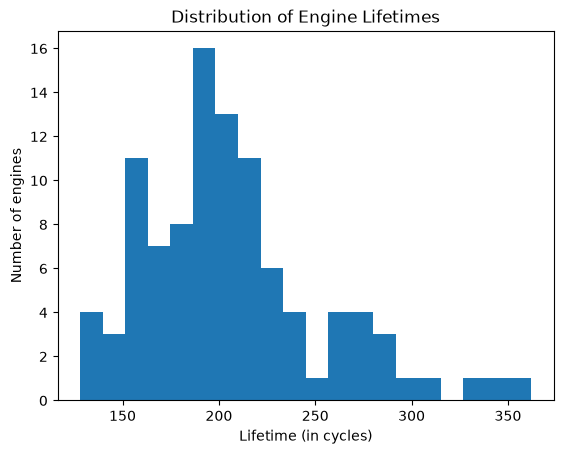

In [38]:
import matplotlib.pyplot as plt

plt.hist(lifetime.values(), bins=20)
plt.xlabel("Lifetime (in cycles)")
plt.ylabel("Number of engines")
plt.title("Distribution of Engine Lifetimes")
plt.show()

Using the histogram we can see that the Lifetime has a big variance. It can therefore not simply be predicted through checking the amount of cycles! And thats what we are gonna do next.